# Phase 11 CNN overfitting audit
2026-11-06. Frozen checkpoint `wavecnn_ccb3b06b3d37`; no training, threshold tuning or dataset changes.
Reuse prior provenance/leakage and robustness checks. Evaluate all splits in eval mode for comparable gaps.
Training-history metrics were measured during updates with dropout/BatchNorm in training mode and are not directly comparable to frozen-checkpoint metrics.
PR-AUC below means trapezoidal precision–recall area; average precision is also saved.
Independent noise stress protocol fixed before execution: seed 20261106, 256 traces each of white Gaussian, low-pass Gaussian (5 Hz cutoff), and impulsive Gaussian noise; 100 Hz, 10,000 samples, identical per-trace detrending/standardization, threshold 0.5. These are negative controls, not an independent earthquake benchmark.

In [1]:
from pathlib import Path
import ast, json, hashlib, os
import numpy as np
import pandas as pd
import h5py, torch
from torch import nn
from scipy.signal import detrend, butter, sosfiltfilt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve, auc, confusion_matrix
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
BASE=Path.cwd()
if not (BASE/'data wave').exists(): BASE=BASE/'cnn'/'cnn wave'
RES=BASE/'phase1_waveform_cnn_results'; EID='wavecnn_ccb3b06b3d37'
OUT=RES/'overfitting_audit'; OUT.mkdir(exist_ok=True)
M=RES/'metrics'/EID; R=RES/'reports'/EID
audit=json.loads((RES/'reports/waveform_audit.json').read_text())
config=json.loads((R/'config.json').read_text())
preprocessing=json.loads((RES/'models'/EID/'preprocessing.json').read_text())
PATHS={s:BASE/audit['splits'][s]['path'] for s in ['train','validation','test']}
expected=BASE/'data wave/synthetic_waveform_simulator/output/phase11_preprocessed_dataset'
assert all(p.resolve()==(expected/f'{s}.h5').resolve() for s,p in PATHS.items())
assert config['waveform_key']==preprocessing['input_key']=='waveforms_standardized'
assert preprocessing['metadata_inputs'] is False
original=BASE/'phase1_waveform_cnn.ipynb'; checkpoint=RES/'models'/EID/'best.pt'
def digest(p):
    with p.open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()
protected=[original,*list((RES/'models'/EID).glob('*')), *PATHS.values()]
before={str(p):(p.stat().st_size,p.stat().st_mtime_ns) for p in protected if p.is_file()}
small_hashes={str(p):digest(p) for p in protected if p.is_file() and p not in PATHS.values()}
def save(name,obj): (OUT/name).write_text(json.dumps(obj,indent=2,default=str,allow_nan=False),encoding='utf-8')
save('provenance.json',dict(experiment=EID,paths={s:str(p.resolve()) for s,p in PATHS.items()},key=config['waveform_key'],preprocessing=preprocessing,cached_checks=audit['checks'],cached_source_hashes=audit['source_hashes'],protected_hashes=small_hashes,method='Prior 2026-11-06 full hash verification reused; dataset size/mtime checked before and after this read-only audit.'))
# Extract only the class definition, never execute original notebook cells.
source=json.loads(original.read_text(encoding='utf-8'))
nodes=[n for c in source['cells'] if c['cell_type']=='code' for n in ast.parse(''.join(c['source'])).body if isinstance(n,ast.ClassDef) and n.name=='WaveformCNN']
assert len(nodes)==1
exec(compile(ast.Module(body=nodes,type_ignores=[]),str(original),'exec'))
torch.set_num_threads(4)
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
state=torch.load(checkpoint,map_location='cpu',weights_only=False)
assert state['config']==config
assert state['dataset_version']==hashlib.sha256(json.dumps(audit['source_hashes'],sort_keys=True).encode()).hexdigest()
model=WaveformCNN().to(DEVICE); model.load_state_dict(state['model']); model.eval()
for p in model.parameters(): p.requires_grad_(False)
history=pd.read_csv(M/'training_history.csv')
assert int(state['epoch'])==int(history.loc[history.validation_loss.idxmin(),'epoch'])
print('Checkpoint epoch',state['epoch'],'device',DEVICE,'input',config['waveform_key'])

Checkpoint epoch 22 device cuda input waveforms_standardized


In [2]:
def measure(y,p,loss):
    pred=p>=.5; precision,recall,_=precision_recall_curve(y,p)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(samples=len(y),loss=float(loss),accuracy=float(accuracy_score(y,pred)),precision=float(precision_score(y,pred,zero_division=0)),recall=float(recall_score(y,pred,zero_division=0)),f1=float(f1_score(y,pred,zero_division=0)),roc_auc=float(roc_auc_score(y,p)),pr_auc=float(auc(recall,precision)),average_precision=float(average_precision_score(y,p)),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))
@torch.inference_mode()
def infer(x):
    return model(torch.from_numpy(np.asarray(x,dtype=np.float32)[:,None,:]).to(DEVICE)).flatten()
rows=[]; predictions={}
for split,path in PATHS.items():
    with h5py.File(path,'r') as f:
        y=f['labels'][:]; n=len(y); prob=np.empty(n); total=0.
        assert f[config['waveform_key']].shape==(n,10000)
        # Match original evaluation batch composition and CUDA settings exactly.
        half=n//2; seen=np.zeros(n,dtype=int)
        for start in range(0,half,config['hdf5_block_rows']):
            stop=min(start+config['hdf5_block_rows'],half)
            indices=np.r_[np.arange(start,stop),np.arange(half+start,half+stop)]
            x=np.concatenate([f[config['waveform_key']][start:stop],f[config['waveform_key']][half+start:half+stop]])
            for j in range(0,len(indices),32):
                rr=indices[j:j+32]; logits=infer(x[j:j+32])
                target=torch.tensor(y[rr],dtype=torch.float32,device=DEVICE)
                total+=nn.functional.binary_cross_entropy_with_logits(logits,target,reduction='sum').item()
                prob[rr]=torch.sigmoid(logits).cpu().numpy(); seen[rr]+=1
        assert (seen==1).all()
    assert np.isfinite(prob).all()
    frame=pd.DataFrame({'row':np.arange(n),'labels':y,'score_CNN':prob,'prediction_CNN':(prob>=.5).astype(int)})
    frame.to_csv(OUT/f'{split}_predictions.csv',index=False); predictions[split]=frame
    rows.append(dict(split=split,**measure(y,prob,total/n)))
    if split!='train':
        old=pd.read_csv(M/f'{split}_predictions.csv').sort_values('row')
        assert np.array_equal(y,old.labels)
        assert np.allclose(prob,old.score_CNN,atol=2e-6,rtol=1e-5), 'Saved prediction mismatch'
metrics=pd.DataFrame(rows).set_index('split'); metrics.to_csv(OUT/'split_metrics.csv')
gaps={}
for other in ['validation','test']:
    gaps['train_minus_'+other+'_accuracy_pp']=float(100*(metrics.loc['train','accuracy']-metrics.loc[other,'accuracy']))
    gaps[other+'_minus_train_loss']=float(metrics.loc[other,'loss']-metrics.loc['train','loss'])
best=history[history.epoch.eq(state['epoch'])].iloc[0]; last=history.iloc[-1]
gaps.update(best_epoch=int(state['epoch']),epochs=len(history),history_best_train_minus_validation_accuracy_pp=float(100*(best.train_accuracy-best.validation_accuracy)),history_final_train_minus_validation_accuracy_pp=float(100*(last.train_accuracy-last.validation_accuracy)),validation_loss_best=float(best.validation_loss),validation_loss_last=float(last.validation_loss),validation_loss_peak_after_best=float(history.loc[history.epoch.gt(state['epoch']),'validation_loss'].max()))
save('gaps.json',gaps)
display(metrics.round(6)); print(json.dumps(gaps,indent=2))

,samples,loss,accuracy,precision,recall,f1,roc_auc,pr_auc,average_precision,tn,fp,fn,tp
split,,,,,,,,,,,,,
train,11324,0.007772,0.997351,0.999114,0.995585,0.997346,0.999978,0.999978,0.999978,5657,5,25,5637
validation,2426,0.010031,0.997115,0.997525,0.996702,0.997113,0.999779,0.999748,0.999748,1210,3,4,1209
test,2428,0.005562,0.998353,0.999175,0.997529,0.998351,0.999995,0.999995,0.999995,1213,1,3,1211


{
  "train_minus_validation_accuracy_pp": 0.023616752810062813,
  "validation_minus_train_loss": 0.0022597701756038287,
  "train_minus_test_accuracy_pp": -0.10017940930518998,
  "test_minus_train_loss": -0.0022090746498188117,
  "best_epoch": 22,
  "epochs": 25,
  "history_best_train_minus_validation_accuracy_pp": -0.17949168943649507,
  "history_final_train_minus_validation_accuracy_pp": 0.07663068436457587,
  "validation_loss_best": 0.0100313095407858,
  "validation_loss_last": 0.0104814531372036,
  "validation_loss_peak_after_best": 0.0179981407780375
}


In [3]:
# Reuse verified metadata and robustness results; do not read upstream phases.
test=pd.read_csv(M/'test_predictions.csv').sort_values('row').reset_index(drop=True)
test['score_CNN']=predictions['test'].score_CNN.to_numpy()
test['prediction_CNN']=(test.score_CNN>=.5).astype(int)
test['error_type']=np.where(test.labels.eq(test.prediction_CNN),'correct',np.where(test.labels.eq(0),'false_positive','false_negative'))
errors=test[test.error_type.ne('correct')]
errors.to_csv(OUT/'test_errors.csv',index=False)
sub=[]
for field,edges,names in [('magnitude',[-np.inf,3,5,np.inf],['M<3','3<=M<5','M>=5']),('snr_db',[-np.inf,10,np.inf],['SNR<10','SNR>=10'])]:
    eq=test[test.labels.eq(1)].copy(); eq['bin']=pd.cut(eq[field],edges,labels=names,right=False)
    for name,part in eq.groupby('bin',observed=True):
        sub.append(dict(field=field,group=str(name),samples=len(part),errors=int(part.prediction_CNN.eq(0).sum()),accuracy=float(part.prediction_CNN.eq(1).mean()),interpretation='Earthquake-only accuracy equals recall; noise has no physical event magnitude/SNR.'))
subgroups=pd.DataFrame(sub); subgroups.to_csv(OUT/'magnitude_snr_metrics.csv',index=False)
old_sub=pd.read_csv(M/'subgroup_metrics.csv'); old_sub.to_csv(OUT/'cached_subgroup_metrics.csv',index=False)
robust=pd.read_csv(M/'shortcut_probes.csv'); robust.to_csv(OUT/'cached_shortcut_probes.csv',index=False)
# Confidence is max(p,1-p); inspect errors as well as correct predictions.
confidence=[]
for split,frame in predictions.items():
    correct=frame.labels.eq(frame.prediction_CNN); c=np.maximum(frame.score_CNN,1-frame.score_CNN)
    confidence.append(dict(split=split,mean_confidence=float(c.mean()),errors=int((~correct).sum()),errors_confidence_ge_099=int(((~correct)&(c>=.99)).sum()),mean_error_confidence=float(c[~correct].mean()) if (~correct).any() else None))
save('confidence_summary.json',confidence)
display(subgroups[['group','samples','errors','accuracy']]); display(errors[['row','error_type','magnitude','snr_db','score_CNN']])

,group,samples,errors,accuracy
0,M<3,195,3,0.984615
1,3<=M<5,888,0,1.000000
2,M>=5,131,0,1.000000
3,SNR<10,699,3,0.995708
4,SNR>=10,515,0,1.000000


,row,error_type,magnitude,snr_db,score_CNN
302,302,false_negative,2.7,1.5,0.361421
533,533,false_negative,2.7,1.5,0.160145
1201,1201,false_negative,2.5,1.5,0.251287
1339,1339,false_positive,NaN,NaN,0.609671


In [4]:
# Independent noise-only stress tests: fixed recipes and seed, no fitting or selection.
rng=np.random.default_rng(20261106); stress=[]
sos=butter(4,5,fs=100,output='sos')
for family in ['white_gaussian','lowpass_gaussian_5hz','impulsive_gaussian']:
    scores=[]
    for batch in range(8):
        x=rng.normal(size=(32,10000)).astype(np.float32)
        if family=='lowpass_gaussian_5hz': x=sosfiltfilt(sos,x,axis=-1)
        if family=='impulsive_gaussian':
            for row in x:
                positions=rng.choice(10000,10,replace=False)
                row[positions]+=rng.normal(0,20,10)
        x=detrend(x,axis=-1,type='linear').astype(np.float32)
        x=((x-x.mean(axis=-1,keepdims=True))/(x.std(axis=-1,keepdims=True)+1e-8)).astype(np.float32)
        scores.extend(torch.sigmoid(infer(x)).cpu().numpy().tolist())
    scores=np.array(scores); fp=int((scores>=.5).sum()); n=len(scores); rate=fp/n
    # Wilson interval for negative-only FPR, not earthquake generalization accuracy.
    z=1.96; den=1+z*z/n; center=(rate+z*z/(2*n))/den
    radius=z*np.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/den
    stress.append(dict(family=family,samples=n,false_positives=fp,false_positive_rate=rate,specificity=1-rate,fpr_ci95_low=max(0.,center-radius),fpr_ci95_high=min(1.,center+radius),mean_earthquake_probability=float(scores.mean())))
    pd.DataFrame({'row':np.arange(n),'labels':0,'score_CNN':scores}).to_csv(OUT/f'stress_{family}_predictions.csv',index=False)
stress=pd.DataFrame(stress); stress.to_csv(OUT/'independent_noise_stress.csv',index=False)
display(stress)

,family,samples,false_positives,false_positive_rate,specificity,fpr_ci95_low,fpr_ci95_high,mean_earthquake_probability
0,white_gaussian,256,0,0.0,1.0,0.0,0.014784,0.000212
1,lowpass_gaussian_5hz,256,0,0.0,1.0,0.0,0.014784,0.000864
2,impulsive_gaussian,256,0,0.0,1.0,0.0,0.014784,0.000003


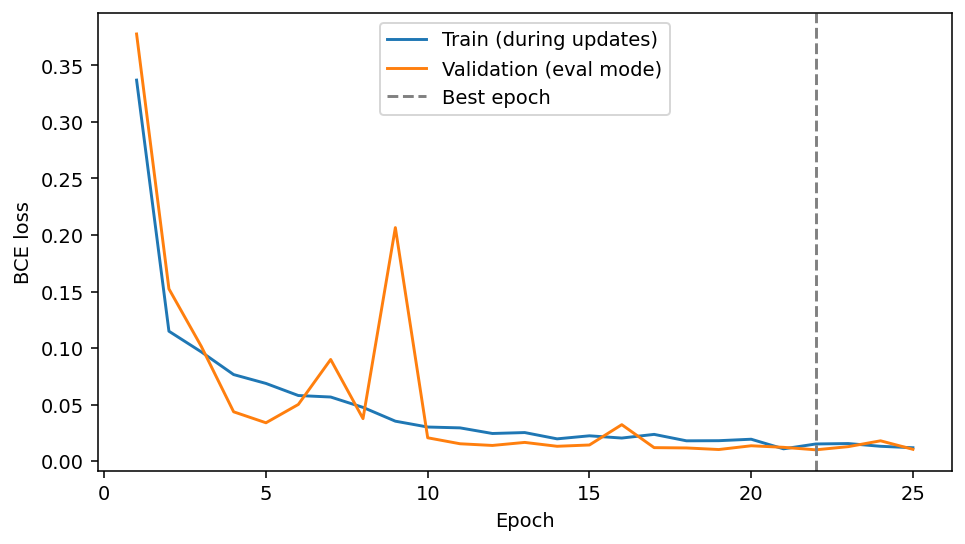

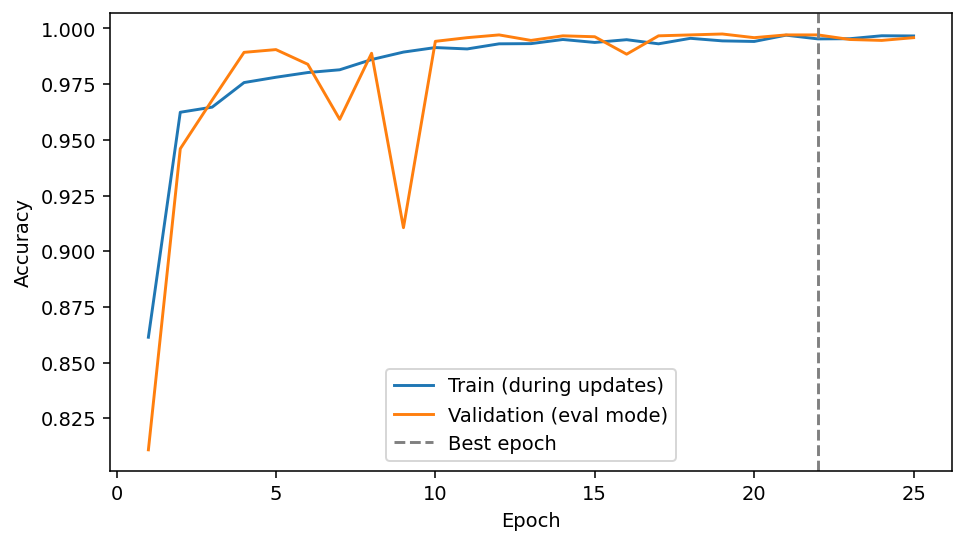

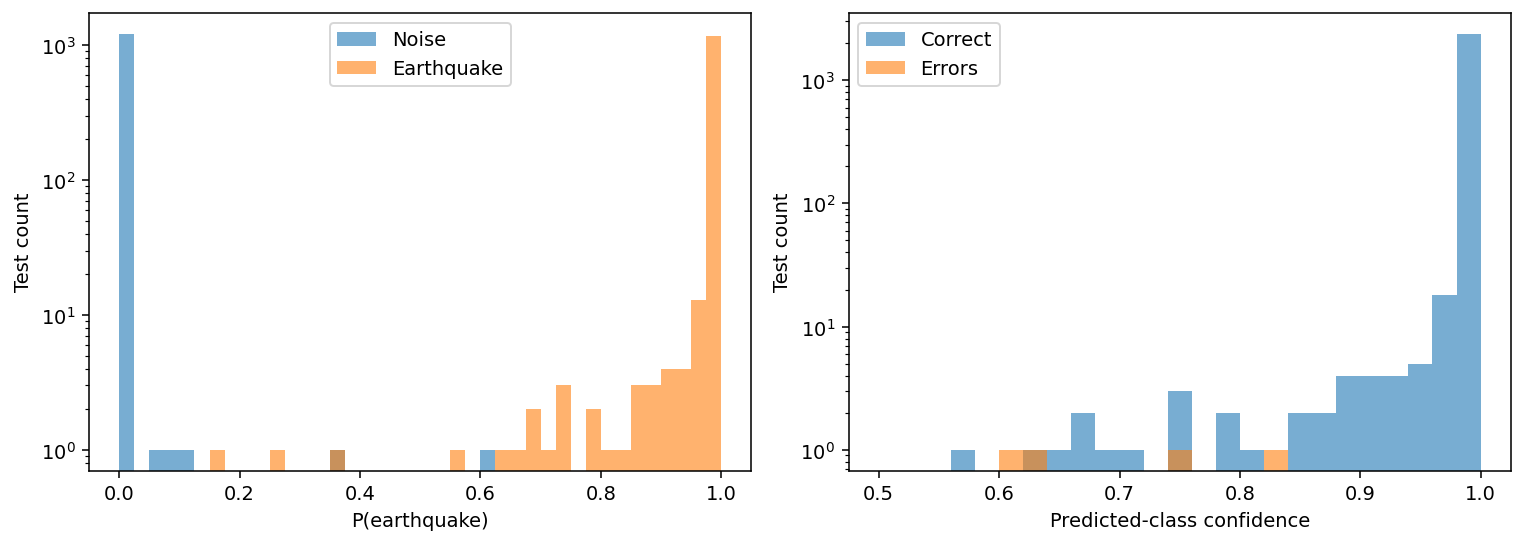

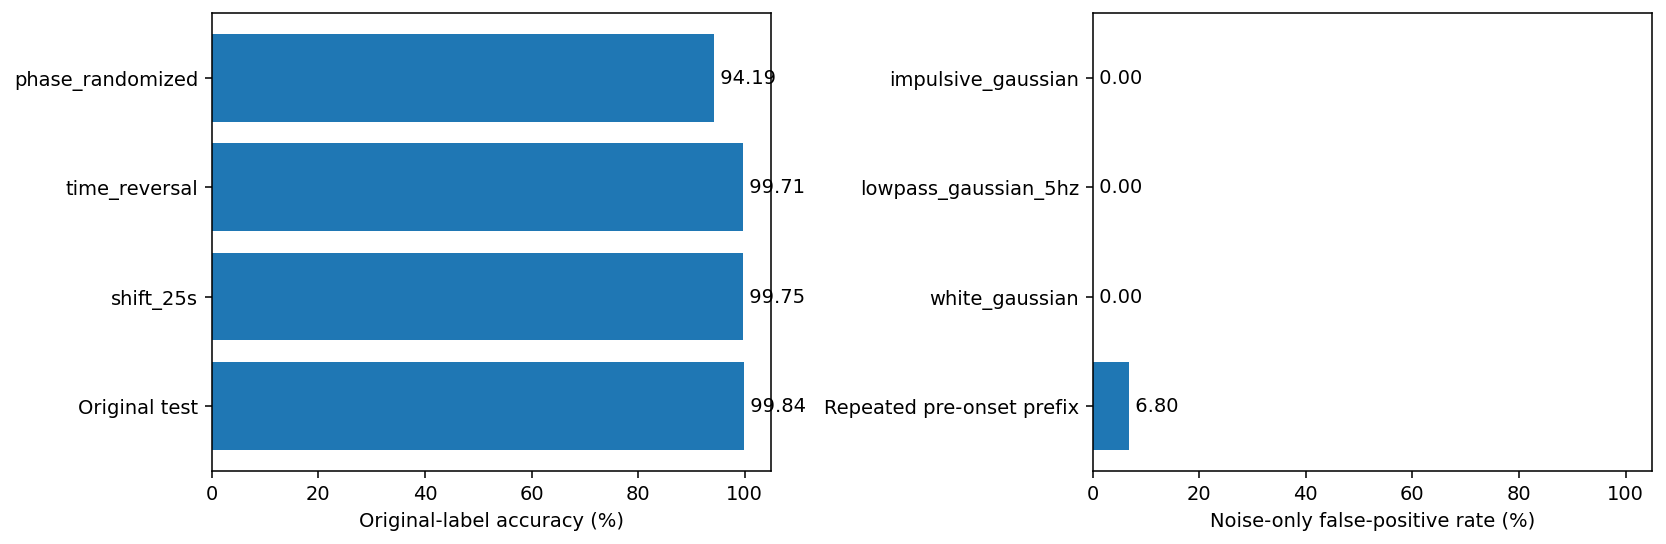

In [5]:
def figure(name):
    plt.tight_layout(); plt.savefig(OUT/name,dpi=140,bbox_inches='tight'); plt.close()
    display(Image(filename=str(OUT/name)))
for metric,title in [('loss','BCE loss'),('accuracy','Accuracy')]:
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(history.epoch,history['train_'+metric],label='Train (during updates)')
    ax.plot(history.epoch,history['validation_'+metric],label='Validation (eval mode)')
    ax.axvline(state['epoch'],color='gray',ls='--',label='Best epoch')
    ax.set(xlabel='Epoch',ylabel=title); ax.legend(); figure('training_validation_'+metric+'.png')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label,name in [(0,'Noise'),(1,'Earthquake')]:
    axes[0].hist(test.loc[test.labels.eq(label),'score_CNN'],bins=np.linspace(0,1,41),alpha=.6,label=name)
axes[0].set(xlabel='P(earthquake)',ylabel='Test count',yscale='log'); axes[0].legend()
conf=np.maximum(test.score_CNN,1-test.score_CNN)
for mask,name in [(test.error_type.eq('correct'),'Correct'),(test.error_type.ne('correct'),'Errors')]:
    axes[1].hist(conf[mask],bins=np.linspace(.5,1,26),alpha=.6,label=name)
axes[1].set(xlabel='Predicted-class confidence',ylabel='Test count',yscale='log'); axes[1].legend()
figure('prediction_confidence.png')
fig,axes=plt.subplots(1,2,figsize=(12,4))
probe=robust[robust.probe.ne('pre_onset_noise_only')]
names=['Original test']+probe.probe.tolist(); vals=[metrics.loc['test','accuracy']]+probe.accuracy.tolist()
axes[0].barh(names,np.array(vals)*100); axes[0].set(xlabel='Original-label accuracy (%)',xlim=(0,105))
for i,v in enumerate(vals): axes[0].text(v*100,i,f' {v*100:.2f}',va='center')
names=['Repeated pre-onset prefix']+stress.family.tolist()
vals=[float(robust.loc[robust.probe.eq('pre_onset_noise_only'),'all_noise_false_positive_rate'].iloc[0])]+stress.false_positive_rate.tolist()
axes[1].barh(names,np.array(vals)*100); axes[1].set(xlabel='Noise-only false-positive rate (%)',xlim=(0,105))
for i,v in enumerate(vals): axes[1].text(v*100,i,f' {v*100:.2f}',va='center')
figure('robustness_summary.png')

In [6]:
after={str(p):(p.stat().st_size,p.stat().st_mtime_ns) for p in protected if p.is_file()}
assert before==after
assert all(digest(Path(p))==h for p,h in small_hashes.items())
assert not model.training and not any(p.requires_grad for p in model.parameters())
assert len(list(OUT.glob('*.png')))==4
save('verification.json',dict(original_notebook_and_model_hashes_unchanged=True,dataset_size_mtime_unchanged=True,datasets_opened_read_only=True,saved_validation_test_predictions_match=True,all_three_splits_evaluated=True,no_training=True,threshold=.5,figures=4,device=str(DEVICE),torch_version=torch.__version__))
report=f"""# Frozen CNN overfitting audit — 2026-11-06
Experiment {EID}; best epoch {state['epoch']}/{len(history)}. No new trained experiment; registry unchanged.

## Comparable best-checkpoint metrics
{metrics.to_string(float_format=lambda v:f'{v:.6f}')}

Accuracy gaps (train minus held out), percentage points: validation {gaps['train_minus_validation_accuracy_pp']:.6f}; test {gaps['train_minus_test_accuracy_pp']:.6f}.
Loss gaps (held out minus train): validation {gaps['validation_minus_train_loss']:.6f}; test {gaps['test_minus_train_loss']:.6f}.
Best validation loss {best.validation_loss:.6f}; final {last.validation_loss:.6f}; peak after best {gaps['validation_loss_peak_after_best']:.6f}. Late fluctuations are not sustained divergence; best weights were restored. History train metrics include dropout and changing weights; use frozen metrics above for gaps. No clear underfitting on these synthetic splits.

## Errors and subgroups
{subgroups[['group','samples','errors','accuracy']].to_string(index=False)}
Test false positives: {int(metrics.loc['test','fp'])}; false negatives: {int(metrics.loc['test','fn'])}. Magnitude/SNR bins are earthquake-only; accuracy equals recall. Noise has no physical earthquake magnitude. The cached noise subgroup report assigns the false positive to transient disturbances. Individual errors are in test_errors.csv; confidence summaries include confidently wrong cases.

## Robustness
Reused circular shift accuracy 0.997529, reversal 0.997117, phase randomization 0.941928 (ROC-AUC 0.973689); repeated pre-onset prefix FPR 0.067957. Prefix original-label AUC 0.563610 is source-class discrimination, not earthquake detection, because all transformed examples are noise. Full-trace detrending and repetition can introduce artifacts.
{stress.to_string(index=False)}
Independent draws above use simple, prespecified noise recipes, not the original generator. They test false alarms only; no earthquake sensitivity or real-field generalization can be inferred. Wilson intervals assume independent generated draws. No threshold, model or recipe was tuned on test outcomes.

## Verdict
Overfitting: No clear evidence of ordinary sample overfitting within the supplied synthetic distribution; this does not establish external generalization. Small frozen-checkpoint gaps and late validation fluctuations must be distinguished from synthetic shortcuts.
Leakage: not detected in completed exact-duplicate, source/pair/event disjointness and label/alignment checks. Exhaustive near-duplicate correlation remains unresolved; shared simulator mechanisms are a distribution limitation, not proven row leakage. Existing complete checks reused, not repeated.
Synthetic shortcuts: evidence consistent with spectral/background discrimination: phase-randomized traces retain high accuracy and time reversal/shift have little effect. This is not causal proof of specific learned features. Noise stress results provide additional negative-only evidence. Full-waveform preprocessing is offline detection, not forecasting.
Ready for BiLSTM comparison: Yes for a controlled synthetic baseline using identical splits, preprocessing and validation selection; no claim of field readiness. Freeze this CNN and threshold. Official test has already been inspected for diagnostics: do not use it to tune architectures or hyperparameters; reserve a new untouched distribution/holdout for claims beyond this benchmark.
"""
(OUT/'audit_report.md').write_text(report,encoding='utf-8')
print('PASS: read-only audit; four figures and detailed metrics saved to',OUT)

PASS: read-only audit; four figures and detailed metrics saved to C:\Users\choud\Desktop\Minor project\cnn\cnn wave\phase1_waveform_cnn_results\overfitting_audit
